# CIFAR-10 Image Classification

## Task 1: Problem & Dataset
Task type: Convolutional neural network (CNN) for single-label, 10-class image classification. Given a 32 × 32 RGB image, the model predicts one object category.

- **Dataset:** CIFAR-10 contains 60,000 labeled images, with 50,000 in the official training split and 10,000 in the official test split (Krizhevsky, 2009). The images are drawn from a collection of real images and are used here for an academic benchmarking exercise.
- **Source:** Visit https://www.cs.toronto.edu/~kriz/cifar.html and download CIFAR-10 binary version (suitable for C programs). Extract it beside this notebook so that data/cifar-10-batches-bin/data_batch_1.bin exists. Keep the five training batch files, the test batch, and batches.meta.txt in that directory.
- **Setup:** In a clean Python environment, install numpy torch matplotlib jupyter with pip, then open this notebook with that environment's kernel and choose Restart Kernel and Run All Cells. Once the environment is validated, run python -m pip freeze > requirements.txt inside it. GPU acceleration is optional.

## Task 2: Load & inspect

Each binary record contains one label byte and 3,072 pixel bytes in channel-first order. Inspect the data before converting images from uint8 in [0, 255] to float32 in [0, 1]. Convert labels to int64 class indices for cross-entropy. Small images can obscure distinguishing details, particularly for similar classes. Both runs use the same preprocessing without augmentation.

Device: cuda
Official training: images (50000, 3, 32, 32) uint8, pixels 0–255
Labels (50000,) int64, class counts [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]
Official test: images (10000, 3, 32, 32) uint8, pixels 0–255
Labels (10000,) int64, class counts [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


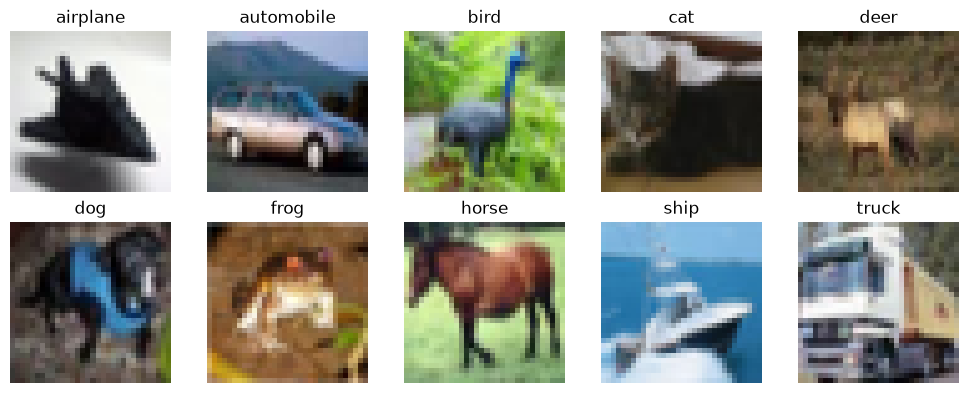

In [1]:
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
BATCH_SIZE = 128
EPOCHS = 8
ROOT = Path("data/cifar-10-batches-bin")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.use_deterministic_algorithms(True, warn_only=True)
torch.backends.cudnn.benchmark = False
print("Device:", DEVICE)

if not (ROOT / "batches.meta.txt").is_file():
    raise FileNotFoundError(f"Extract the official CIFAR-10 binary archive into {ROOT}.")

classes = [
    line.strip()
    for line in (ROOT / "batches.meta.txt").read_text().splitlines()
    if line.strip()
]
assert len(classes) == 10, f"Expected 10 class names, got {len(classes)}: {classes!r}"

def load_batch(filename):
    records = np.fromfile(ROOT / filename, dtype=np.uint8).reshape(-1, 3073)
    assert records.shape[0] == 10_000
    return records[:, 1:].reshape(-1, 3, 32, 32), records[:, 0].astype(np.int64)

batches = [load_batch(f"data_batch_{i}.bin") for i in range(1, 6)]
images = np.concatenate([batch[0] for batch in batches])
labels = np.concatenate([batch[1] for batch in batches])
del batches
test_images, test_labels = load_batch("test_batch.bin")
assert len(classes) == 10
for name, x, y in [("Official training", images, labels), ("Official test", test_images, test_labels)]:
    assert len(x) == len(y) and ((0 <= y) & (y < len(classes))).all()
    print(f"{name}: images {x.shape} {x.dtype}, pixels {x.min()}–{x.max()}")
    print(f"Labels {y.shape} {y.dtype}, class counts {np.bincount(y, minlength=len(classes))}")

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    index = np.flatnonzero(labels == i)[0]
    ax.imshow(images[index].transpose(1, 2, 0))
    ax.set_title(classes[i])
    ax.axis("off")
plt.tight_layout()
plt.show()

In [2]:
# Hold out 500 examples per class from the official training split.
rng = np.random.default_rng(SEED)
val_idx = np.concatenate([
    rng.permutation(np.flatnonzero(labels == i))[:500] for i in range(len(classes))
])
train_idx = np.setdiff1d(np.arange(len(labels)), val_idx)
assert len(train_idx) == 45_000 and len(val_idx) == 5_000

# Keep dataset tensors compact. Convert pixels to float inside each batch.
train_data = TensorDataset(torch.from_numpy(images[train_idx]), torch.from_numpy(labels[train_idx]))
val_data = TensorDataset(torch.from_numpy(images[val_idx]), torch.from_numpy(labels[val_idx]))
test_data = TensorDataset(torch.from_numpy(test_images), torch.from_numpy(test_labels))
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE)
print("Train / validation / test:", len(train_data), len(val_data), len(test_data))

Train / validation / test: 45000 5000 10000


## Task 3: Baseline model

Three 3 × 3 convolution layers with padding learn local patterns while preserving spatial dimensions within each block. ReLU adds nonlinearity, and 2 × 2 max pooling halves the spatial dimensions after each block. The channel count grows from 32 to 64 to 128 as the spatial grid shrinks to 4 × 4, following the general convolution-and-pooling design described by LeCun et al. (1998). The linear classifier maps the flattened 2,048 features to 10 raw logits. Cross-entropy consumes logits directly, and Adam starts with a learning rate of 0.001.

In [3]:
class CifarCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(128 * 4 * 4, len(classes))

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))

torch.manual_seed(SEED)
initial_state = deepcopy(CifarCNN().state_dict())
criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum = correct = count = 0
    with torch.set_grad_enabled(training):
        for images_batch, targets in loader:
            x = images_batch.to(DEVICE, dtype=torch.float32) / 255.0
            y = targets.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                loss.backward()
                optimizer.step()
            count += y.numel()
            loss_sum += loss.item() * y.numel()
            correct += (logits.argmax(dim=1) == y).sum().item()
    return loss_sum / count, correct / count

def train_model(learning_rate):
    torch.manual_seed(SEED)
    model = CifarCNN()
    model.load_state_dict(initial_state)
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    generator = torch.Generator().manual_seed(SEED)
    loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, generator=generator)
    history = []
    for epoch in range(1, EPOCHS + 1):
        train_loss, train_acc = run_epoch(model, loader, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader)
        history.append((train_loss, train_acc, val_loss, val_acc))
        print(f"Epoch {epoch:02d} | train loss {train_loss:.3f}, acc {train_acc:.2%} "
              f"| val loss {val_loss:.3f}, acc {val_acc:.2%}")
    return model, np.array(history)

baseline, baseline_history = train_model(0.001)

Epoch 01 | train loss 1.595, acc 42.25% | val loss 1.351, acc 51.68%
Epoch 02 | train loss 1.235, acc 56.34% | val loss 1.148, acc 59.76%
Epoch 03 | train loss 1.062, acc 63.02% | val loss 1.012, acc 64.94%
Epoch 04 | train loss 0.942, acc 67.24% | val loss 0.940, acc 66.86%
Epoch 05 | train loss 0.861, acc 70.20% | val loss 0.861, acc 70.62%
Epoch 06 | train loss 0.800, acc 72.42% | val loss 0.864, acc 70.12%
Epoch 07 | train loss 0.745, acc 74.32% | val loss 0.822, acc 71.96%
Epoch 08 | train loss 0.695, acc 76.14% | val loss 0.837, acc 71.08%


## Task 4: Experiment	

Change only Adam's learning rate, from 0.001 to 0.0003. Smaller steps may produce smoother progress, but could also take longer to reach comparable accuracy within eight epochs. Both runs share the same starting weights, seed, split, minibatch order, batch size, preprocessing, architecture, loss, Adam defaults apart from learning rate, and epoch budget. Compare the final epoch of each run on the official test split.

In [4]:
experiment, experiment_history = train_model(0.0003)

Epoch 01 | train loss 1.772, acc 35.69% | val loss 1.526, acc 45.66%
Epoch 02 | train loss 1.429, acc 48.84% | val loss 1.360, acc 51.18%
Epoch 03 | train loss 1.310, acc 53.36% | val loss 1.279, acc 54.62%
Epoch 04 | train loss 1.232, acc 56.60% | val loss 1.187, acc 57.88%
Epoch 05 | train loss 1.172, acc 58.88% | val loss 1.150, acc 60.06%
Epoch 06 | train loss 1.128, acc 60.68% | val loss 1.143, acc 59.20%
Epoch 07 | train loss 1.080, acc 62.43% | val loss 1.106, acc 61.68%
Epoch 08 | train loss 1.042, acc 63.97% | val loss 1.042, acc 64.02%


## Task 5: Evaluate & compare

Use accuracy to measure the overall share of correct predictions and macro F1 to give each class equal weight. Read confusion matrix rows as true labels and columns as predictions. Compare the learning curves and inspect the most frequent off-diagonal error for the higher-accuracy model.

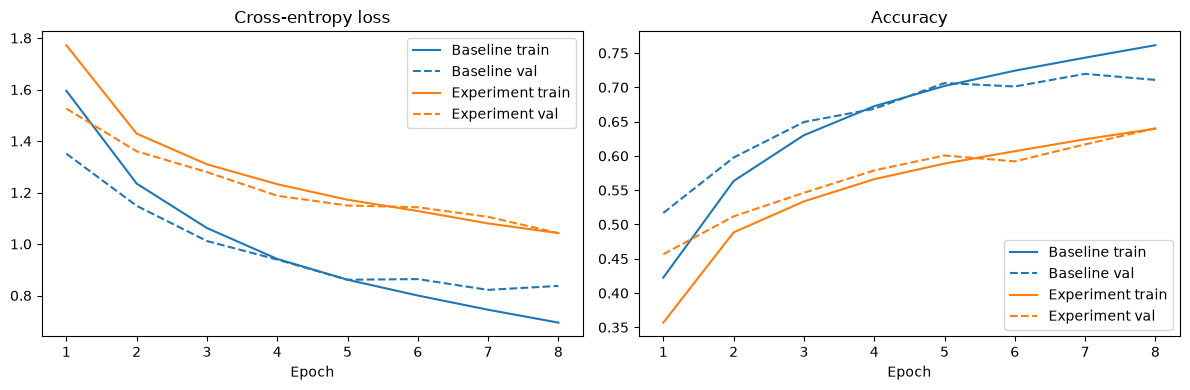

Baseline: test accuracy 70.40% | macro F1 0.7008
Experiment: test accuracy 63.18% | macro F1 0.6303


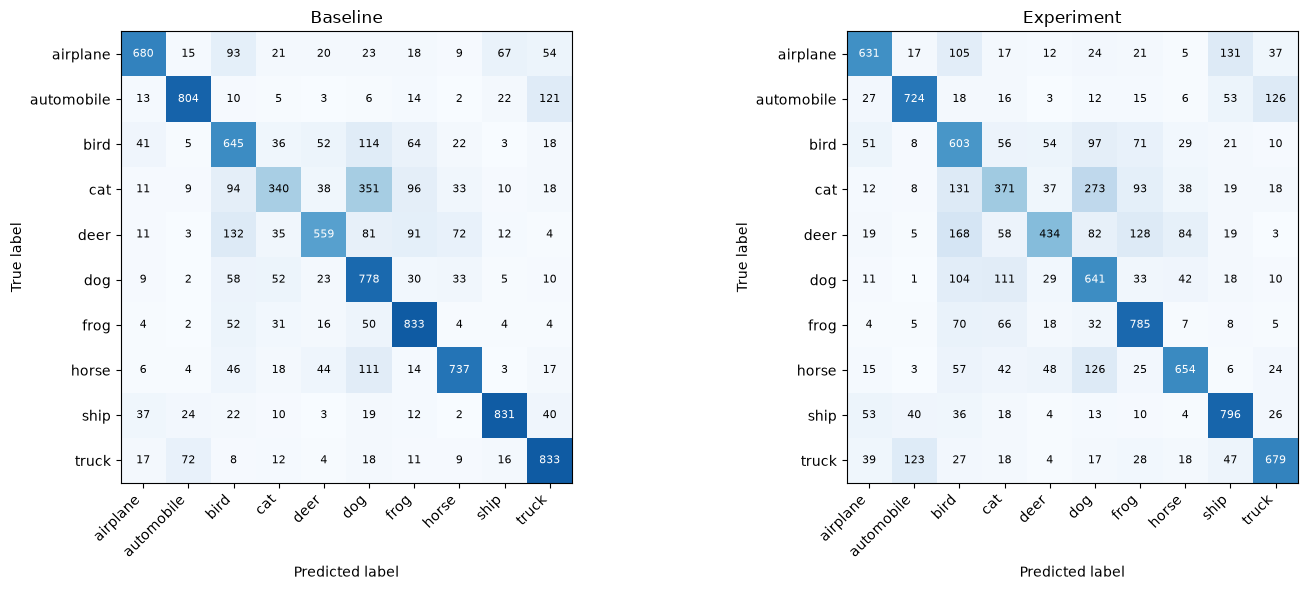

Experiment minus baseline test accuracy: -7.22 percentage points
Baseline final train–validation accuracy gap: +5.06 pp
Experiment final train–validation accuracy gap: -0.05 pp
Baseline: 351 true cat images predicted as dog. Example test index: 0.


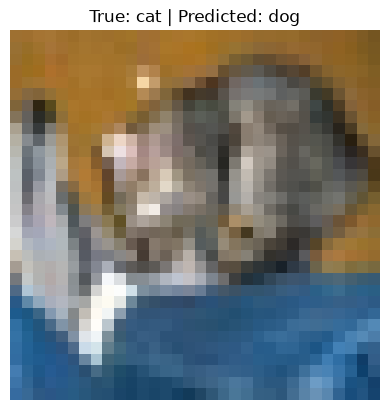

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = np.arange(1, EPOCHS + 1)
for name, history in [("Baseline", baseline_history), ("Experiment", experiment_history)]:
    for ax, train_col, val_col, title in [
        (axes[0], 0, 2, "Cross-entropy loss"),
        (axes[1], 1, 3, "Accuracy"),
    ]:
        line, = ax.plot(epochs, history[:, train_col], label=f"{name} train")
        ax.plot(epochs, history[:, val_col], "--", color=line.get_color(), label=f"{name} val")
        ax.set(xlabel="Epoch", title=title)
        ax.legend()
plt.tight_layout()
plt.show()

@torch.inference_mode()
def evaluate(model):
    model.eval()
    predictions = []
    for batch, _ in test_loader:
        logits = model(batch.to(DEVICE, dtype=torch.float32) / 255.0)
        predictions.append(logits.argmax(dim=1).cpu().numpy())
    predicted = np.concatenate(predictions)
    matrix = np.zeros((len(classes), len(classes)), dtype=np.int64)
    np.add.at(matrix, (test_labels, predicted), 1)
    tp = matrix.diagonal()
    denominator = matrix.sum(axis=0) + matrix.sum(axis=1)
    f1 = np.divide(2 * tp, denominator, out=np.zeros(len(classes)), where=denominator != 0)
    return tp.sum() / matrix.sum(), f1.mean(), matrix, predicted

results = {"Baseline": evaluate(baseline), "Experiment": evaluate(experiment)}
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (name, (accuracy, f1, matrix, _)) in zip(axes, results.items()):
    print(f"{name}: test accuracy {accuracy:.2%} | macro F1 {f1:.4f}")
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1000)
    ax.set(xticks=range(10), yticks=range(10), yticklabels=classes,
           xlabel="Predicted label", ylabel="True label", title=name)
    ax.set_xticklabels(classes, rotation=45, ha="right")
    for (row, col), value in np.ndenumerate(matrix):
        ax.text(col, row, str(value), ha="center", va="center",
                color="white" if value > 500 else "black", fontsize=8)
plt.tight_layout()
plt.show()

delta = results["Experiment"][0] - results["Baseline"][0]
print(f"Experiment minus baseline test accuracy: {100 * delta:+.2f} percentage points")
for name, history in [("Baseline", baseline_history), ("Experiment", experiment_history)]:
    print(f"{name} final train–validation accuracy gap: {100 * (history[-1, 1] - history[-1, 3]):+.2f} pp")

best_name = max(results, key=lambda name: results[name][0])
_, _, matrix, predicted = results[best_name]
errors = matrix.copy()
np.fill_diagonal(errors, 0)
if errors.max() > 0:
    true_class, predicted_class = np.unravel_index(errors.argmax(), errors.shape)
    example = np.flatnonzero((test_labels == true_class) & (predicted == predicted_class))[0]
    print(f"{best_name}: {errors[true_class, predicted_class]} true {classes[true_class]} "
          f"images predicted as {classes[predicted_class]}. Example test index: {example}.")
    plt.imshow(test_images[example].transpose(1, 2, 0))
    plt.title(f"True: {classes[true_class]} | Predicted: {classes[predicted_class]}")
    plt.axis("off")
    plt.show()

## Task 6: Summary

This project uses CIFAR-10 to classify 32 × 32 RGB images into ten object categories. The baseline CNN uses Adam with a learning rate of 0.001. The second model starts from the same weights and uses a learning rate of 0.0003 with the same training setup. On the official test set, the baseline reached [baseline accuracy] and the second model reached [experiment accuracy], a difference of [signed difference in percentage points]. The [model name] confused [true class] with [predicted class] on [count] test images, including example [test index].

Note:
    
References
Krizhevsky, A. (2009). Learning multiple layers of features from tiny images [Technical report]. University of Toronto. https://www.cs.toronto.edu/~kriz/learning-features-2009-TR.pdf

LeCun, Y., Bottou, L., Bengio, Y., & Haffner, P. (1998). Gradient-based learning applied to document recognition. Proceedings of the IEEE, 86(11), 2278–2324. https://doi.org/10.1109/5.726791